In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [3]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [4]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

In [5]:
observables = ['evid','xsec','pt','n','parton','nch','pt1','q1','eta1','phi1','pid1','parent1','pt2','q2','eta2','phi2','pid2','parent2',\
              'dr','m']

In [6]:
files = ['/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_11pthat15_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_15pthat20_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_20pthat25_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_25pthat30_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_30pthat35_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_35pthat40_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_40pthat45_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_45pthat50_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_50pthat1000_rc_truth.txt']

In [7]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [8]:
df = applyCut(df, 'pt>20')

In [9]:
print('number of jets with q1 == -1:', df[df.q1==-1].shape[0])
print('number of jets with q1 == +1:', df[df.q1==1].shape[0])

number of jets with q1 == -1: 693358
number of jets with q1 == +1: 930252


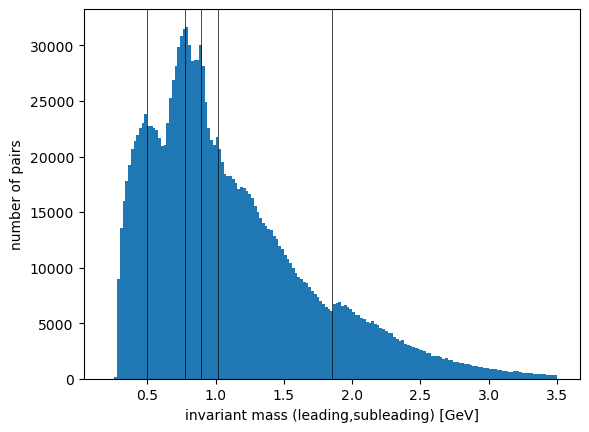

In [10]:
plt.hist(df['m'], bins=np.arange(0.2, 3.52, 0.02))
plt.xlabel('invariant mass (leading,subleading) [GeV]')
plt.ylabel('number of pairs')
plt.axvline(0.498, color='k', linewidth=0.5) # K0L,K0S? pid==130,310
plt.axvline(0.775, color='k', linewidth=0.5) # rho, found
plt.axvline(0.892, color='k', linewidth=0.5) # K*, found
plt.axvline(1.019, color='k', linewidth=0.5) # phi, pid==333
plt.axvline(1.850, color='k', linewidth=0.5) # ???

In [11]:
print(sum(df[df.parent1!=81]['w'])/sum(df['w']))
print(sum(df[df.parent2!=81]['w'])/sum(df['w']))

0.6723120236079407
0.7356540215306834


In [12]:
unique_parent1_array = np.unique(df['parent1'])
unique_parent2_array = np.unique(df['parent2'])

In [13]:
print(unique_parent2_array)

[-9000211  -100323  -100321  -100313  -100311  -100213  -100211   -33122
   -30323   -30313   -30213   -23322   -23312   -23222   -23212   -23122
   -23112   -22212   -22112   -20533   -20523   -20513   -20433   -20423
   -20413   -20325   -20323   -20315   -20313   -20213   -14122   -13322
   -13312   -13222   -13212   -13122   -13112   -12212   -12112   -10533
   -10531   -10523   -10521   -10513   -10511   -10433   -10423   -10421
   -10413   -10411   -10325   -10323   -10321   -10315   -10313   -10311
   -10215   -10213   -10211    -5332    -5232    -5224    -5222    -5132
    -5122    -5114    -5112    -4332    -4314    -4232    -4224    -4222
    -4132    -4122    -4114    -4112    -3334    -3324    -3314    -3312
    -3224    -3222    -3214    -3124    -3122    -3114    -3112    -2224
    -2214    -2114    -1114     -535     -531     -525     -521     -515
     -511     -435     -431     -425     -421     -415     -413     -411
     -327     -325     -323     -317     -315     -

# List parent PIDs and probabilities

In [19]:
pid_array = []
prob_array = []
df_211 = applyCut(df, 'pid2==211')
prob_tot = 0
print('subleading track pid: 211')
for unique_parent2 in unique_parent2_array:
    prob = sum(df_211[df_211.parent2==unique_parent2]['w'])/sum(df_211['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2, ', probability:', prob)
    pid_array.append(str(unique_parent2))
    #prob_array.append([prob])
    prob_array.append(prob)
    prob_tot += prob

subleading track pid: 211
subleading track parent pid: -313 , probability: 0.0206557798535436
subleading track parent pid: 81 , probability: 0.22435607461139923
subleading track parent pid: 113 , probability: 0.183560268778116
subleading track parent pid: 115 , probability: 0.01084456664610505
subleading track parent pid: 213 , probability: 0.2211412365243356
subleading track parent pid: 215 , probability: 0.013462895626399542
subleading track parent pid: 223 , probability: 0.0424641291959634
subleading track parent pid: 225 , probability: 0.026391471909037165
subleading track parent pid: 323 , probability: 0.038168096068946736
subleading track parent pid: 10213 , probability: 0.017164996839366
subleading track parent pid: 30213 , probability: 0.010399440085743996
subleading track parent pid: 9000211 , probability: 0.013446370732923218


In [20]:
prob_tot

0.999999999988409

In [ ]:
# 113: rho0, 213: rho+, 223: omega, 313: K*0, 323: K*+

In [34]:
pid_array = []
prob_array = []
df_n211 = applyCut(df, 'pid2==-211')
print('subleading track pid: -211')
for unique_parent2 in unique_parent2_array:
    prob = sum(df_n211[df_n211.parent2==unique_parent2]['w'])/sum(df_n211['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2, ', probability:', prob)
    pid_array.append(str(unique_parent2))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: -211
subleading track parent pid: -9000211 , probability: 0.013326621464679339
subleading track parent pid: -100213 , probability: 0.011164453475995132
subleading track parent pid: -10213 , probability: 0.017252980330152413
subleading track parent pid: -323 , probability: 0.02372351144076058
subleading track parent pid: -215 , probability: 0.012823019847555147
subleading track parent pid: -213 , probability: 0.2108875398134556
subleading track parent pid: 81 , probability: 0.20764123530897305
subleading track parent pid: 113 , probability: 0.19452639891457515
subleading track parent pid: 223 , probability: 0.04674159225067099
subleading track parent pid: 225 , probability: 0.02516306618303632
subleading track parent pid: 313 , probability: 0.03149127889199348
subleading track parent pid: 20113 , probability: 0.012993385634159194


In [35]:
pid_array = []
prob_array = []
df_321 = applyCut(df, 'pid2==321')
print('subleading track pid: 321')
for unique_parent2 in unique_parent2_array:
    prob = sum(df_321[df_321.parent2==unique_parent2]['w'])/sum(df_321['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2, ', probability:', prob)
    pid_array.append(str(unique_parent2))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: 321
subleading track parent pid: -421 , probability: 0.01681397212417925
subleading track parent pid: 81 , probability: 0.33359788336600593
subleading track parent pid: 225 , probability: 0.012584444462141669
subleading track parent pid: 313 , probability: 0.25494034117353775
subleading track parent pid: 315 , probability: 0.023389533442926744
subleading track parent pid: 323 , probability: 0.12601097938862335
subleading track parent pid: 325 , probability: 0.016134620597058266
subleading track parent pid: 333 , probability: 0.016000975705516434
subleading track parent pid: 335 , probability: 0.01095865953030371
subleading track parent pid: 10311 , probability: 0.02046751086880525
subleading track parent pid: 10313 , probability: 0.01491448887912953
subleading track parent pid: 10323 , probability: 0.01652577098515676
subleading track parent pid: 10325 , probability: 0.010308811890368487
subleading track parent pid: 9000111 , probability: 0.015641659457687616
subl

In [ ]:
# 313: K*0, 323: K*+, 333: phi, 421: D0

In [36]:
pid_array = []
prob_array = []
df_n321 = applyCut(df, 'pid2==-321')
print('subleading track pid: -321')
for unique_parent2 in unique_parent2_array:
    prob = sum(df_n321[df_n321.parent2==unique_parent2]['w'])/sum(df_n321['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2, ', probability:', prob)
    pid_array.append(str(unique_parent2))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: -321
subleading track parent pid: -9000211 , probability: 0.026577507469661255
subleading track parent pid: -30313 , probability: 0.010170842749137888
subleading track parent pid: -10323 , probability: 0.012891840226237709
subleading track parent pid: -10313 , probability: 0.01304707892128345
subleading track parent pid: -10311 , probability: 0.015339934534810461
subleading track parent pid: -327 , probability: 0.010258871391681766
subleading track parent pid: -325 , probability: 0.010115899339731473
subleading track parent pid: -323 , probability: 0.14509265333203655
subleading track parent pid: -315 , probability: 0.015553125961792461
subleading track parent pid: -313 , probability: 0.2332328816697761
subleading track parent pid: 81 , probability: 0.3362375423657097
subleading track parent pid: 333 , probability: 0.02182714476406211
subleading track parent pid: 421 , probability: 0.014730344746925486
subleading track parent pid: 9000111 , probability: 0.01731543

In [37]:
pid_array = []
prob_array = []
df_2212 = applyCut(df, 'pid2==2212')
print('subleading track pid: 2212')
for unique_parent2 in unique_parent2_array:
    prob = sum(df_2212[df_2212.parent2==unique_parent2]['w'])/sum(df_2212['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2, ', probability:', prob)
    pid_array.append(str(unique_parent2))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: 2212
subleading track parent pid: 81 , probability: 0.5594502650874604
subleading track parent pid: 2114 , probability: 0.04663741085249378
subleading track parent pid: 2214 , probability: 0.10523525588278757
subleading track parent pid: 2224 , probability: 0.17037640780779423
subleading track parent pid: 12112 , probability: 0.024049184350378013
subleading track parent pid: 12212 , probability: 0.022149965695722074
subleading track parent pid: 22112 , probability: 0.015692791302692927
subleading track parent pid: 22212 , probability: 0.042032604344246556


In [48]:
# 2114: Delta0, 2214: Delta+, 2224: Delta++

In [38]:
pid_array = []
prob_array = []
df_n2212 = applyCut(df, 'pid2==-2212')
print('subleading track pid: -2212')
for unique_parent2 in unique_parent2_array:
    prob = sum(df_n2212[df_n2212.parent2==unique_parent2]['w'])/sum(df_n2212['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2, ', probability:', prob)
    pid_array.append(str(unique_parent2))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: -2212
subleading track parent pid: -22212 , probability: 0.05321218504609494
subleading track parent pid: -22112 , probability: 0.0165275033788711
subleading track parent pid: -12212 , probability: 0.02542461046876639
subleading track parent pid: -12112 , probability: 0.03092395703445915
subleading track parent pid: -2224 , probability: 0.1512948312053162
subleading track parent pid: -2214 , probability: 0.09423004799330216
subleading track parent pid: -2114 , probability: 0.0622912023519806
subleading track parent pid: 81 , probability: 0.5482610345214006


# Assign specific codes to sign preserving decays

In [39]:
parent1_new = []
parent2_new = []
for i in range(0, df.shape[0]):
    parent1 = df.iloc[i]['parent1']
    parent2 = df.iloc[i]['parent2']
    pid1 = df.iloc[i]['pid1']
    pid2 = df.iloc[i]['pid2']
    if (parent1 == 81):
        parent1_new.append(-998)
    elif ((abs(pid1) == 211 or abs(pid1) == 321) and (abs(parent1) == 213 or abs(parent1) == 323)): # sign preserving decay
        parent1_new.append(-997)
    elif (abs(pid1) == 2212 and (abs(parent1) == 2214 or abs(parent1) == 2224)):
        parent1_new.append(-997)
    else:
        parent1_new.append(parent1)
    if (parent2 == 81):
        parent2_new.append(-998)
    elif ((abs(pid2) == 211 or abs(pid2) == 321) and (abs(parent2) == 213 or abs(parent2) == 323)): # sign preserving decay
        parent2_new.append(-997)
    elif (abs(pid2) == 2212 and (abs(parent2) == 2214 or abs(parent2) == 2224)):
        parent2_new.append(-997)
    else:
        parent2_new.append(parent2)

In [40]:
df['parent1_new'] = parent1_new
df['parent2_new'] = parent2_new

In [41]:
print(sum(df[(df.parent1_new!=-998) & (df.parent1_new!=-997)]['w'])/sum(df['w']))
print(sum(df[(df.parent2_new!=-998) & (df.parent2_new!=-997)]['w'])/sum(df['w']))

0.4548820944771301
0.5073052254980445


In [42]:
df.eval('b_ch = q1*q2', inplace=True)
df_signal = applyCut(df, '-999<=parent1_new<=-997 and -999<=parent2_new<=-997')
#df_nondecay = applyCut(df, 'parent1==-999 and parent2==-999')
#df_samesigndecay = applyCut(df, 'parent1==-997 and parent2==-997')
df_onedecay = applyCut(df, '(-999<=parent1_new<=-997 and (parent2_new<-999 or parent2_new>-997)) or\
                            (-999<=parent2_new<=-997 and (parent1_new<-999 or parent1_new>-997))')
df_twodecay = applyCut(df, '(parent1_new<-999 or parent1_new>-997) and (parent2_new<-999 or parent2_new>-997)')

In [43]:
df_array = [ df[(df.pt>20) & (df.pt<25)],\
            df[(df.pt>25) & (df.pt<30)],\
            df[(df.pt>30) & (df.pt<40)] ]

In [44]:
rc_array = []
rc_err_array = []
for i in range(0, len(df_array)):
    rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

In [45]:
df_signal_array = [ df_signal[(df_signal.pt>20) & (df_signal.pt<25)],\
            df_signal[(df_signal.pt>25) & (df_signal.pt<30)],\
            df_signal[(df_signal.pt>30) & (df_signal.pt<40)] ]

In [46]:
signal_rc_array = []
signal_rc_err_array = []
for i in range(0, len(df_signal_array)):
    signal_rc_array.append(getRcAndErr(df_signal_array[i], 'b_ch')[0])
    signal_rc_err_array.append(getRcAndErr(df_signal_array[i], 'b_ch')[1])

In [47]:
df_onedecay_array = [ df_onedecay[(df_onedecay.pt>20) & (df_onedecay.pt<25)],\
            df_onedecay[(df_onedecay.pt>25) & (df_onedecay.pt<30)],\
            df_onedecay[(df_onedecay.pt>30) & (df_onedecay.pt<40)] ]

In [48]:
onedecay_rc_array = []
onedecay_rc_err_array = []
for i in range(0, len(df_onedecay_array)):
    onedecay_rc_array.append(getRcAndErr(df_onedecay_array[i], 'b_ch')[0])
    onedecay_rc_err_array.append(getRcAndErr(df_onedecay_array[i], 'b_ch')[1])

In [49]:
df_twodecay_array = [ df_twodecay[(df_twodecay.pt>20) & (df_twodecay.pt<25)],\
            df_twodecay[(df_twodecay.pt>25) & (df_twodecay.pt<30)],\
            df_twodecay[(df_twodecay.pt>30) & (df_twodecay.pt<40)] ]

In [50]:
twodecay_rc_array = []
twodecay_rc_err_array = []
for i in range(0, len(df_twodecay_array)):
    twodecay_rc_array.append(getRcAndErr(df_twodecay_array[i], 'b_ch')[0])
    twodecay_rc_err_array.append(getRcAndErr(df_twodecay_array[i], 'b_ch')[1])

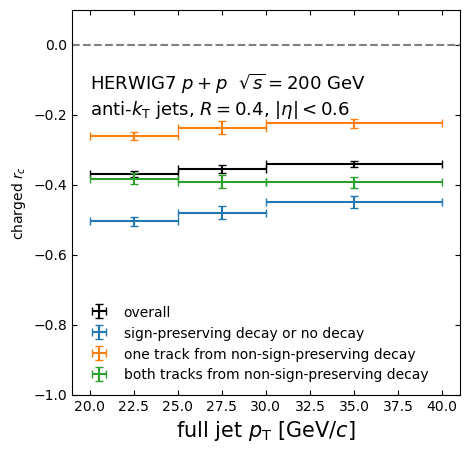

In [53]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_array, xerr=[2.5, 2.5, 5], yerr=rc_err_array, capsize=3, ls='none', label='overall', color='k')
plt.errorbar([22.5, 27.5, 35], signal_rc_array, xerr=[2.5, 2.5, 5], yerr=signal_rc_err_array, capsize=3, ls='none', label='sign-preserving decay or no decay')
plt.errorbar([22.5, 27.5, 35], onedecay_rc_array, xerr=[2.5, 2.5, 5], yerr=onedecay_rc_err_array, capsize=3, ls='none', label='one track from non-sign-preserving decay')
plt.errorbar([22.5, 27.5, 35], twodecay_rc_array, xerr=[2.5, 2.5, 5], yerr=twodecay_rc_err_array, capsize=3, ls='none', label='both tracks from non-sign-preserving decay')
plt.axhline(y=0.0, color='grey', linestyle='--')
#plt.text(20,0.025, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel(r'full jet $p_{\mathrm{T}}$ [GeV$/c$]', fontsize=15)
plt.text(20,-0.2,'HERWIG7 $p+p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-1,0.1)
plt.legend(fontsize=10, loc='lower left', frameon=False)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')